# Imports

In [131]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import base64
import seaborn as sns

In [132]:
import pickle

In [133]:
import ast

In [134]:
import ratinabox
from ratinabox.Environment import Environment
from ratinabox.Agent import Agent
from ratinabox.Neurons import FieldOfViewOVCs
# from ratinabox.Neurons import PlaceCells, GridCells #...

## aux funcs

In [135]:
import random
import string

def generate_random_string(n):
    """
    Generate a random string of length n.

    Parameters:
    n (int): The desired length of the string.

    Returns:
    str: A random string of length n.
    """
    if n <= 0:
        raise ValueError("Length 'n' must be a positive integer.")

    # Combine letters, digits, and punctuation
    characters = string.ascii_uppercase
    
    # Generate a random string of length n
    random_string = ''.join(random.choices(characters, k=n))

    return random_string


In [136]:
generate_random_string(8)

'NPIMXQVO'

In [137]:
def generate_all_positions_on_env(hole=None):

        # Define the range and step size
    step = 0.001  # Adjust the step size for granularity
    x_range = np.arange(0, 1 + step, step)
    y_range = np.arange(0, 1 + step, step)

    # Create a grid of (x, y) positions
    x, y = np.meshgrid(x_range, y_range)
    positions = np.column_stack([x.ravel(), y.ravel()])

    # Convert to a pandas DataFrame
    df_positions = pd.DataFrame(positions, columns=["X", "Y"])
    # df_positions['is_valid'] = [int(is_point_valid(pos, hole)) for pos in positions]
    df_positions['pos'] = [val for val in positions]

    return df_positions

In [138]:
def get_euclidean_distance(pos1, pos2):
    return np.sqrt((pos1[0] - pos2[0])**2 + ((pos1[1] - pos2[1])**2))
def apply_eucd_dist(x, obj=9):
    return get_euclidean_distance(x['pos'], x[f'obj_{obj}_pos'])

In [139]:
def gerar_grade_quadrada(n):
    """
    Gera uma lista de pontos (x, y) uniformemente distribuídos
    em uma grade quadrada dentro do domínio [0, 1] x [0, 1].

    Parâmetros:
        n (int): número de divisões por eixo (resultando em n x n pontos)

    Retorna:
        lista de tuplas (x, y)
    """
    pontos = []
    passo = 1.0 / (n - 1)  # para incluir o ponto 1.0 no final

    for i in range(n):
        x = i * passo
        for j in range(n):
            y = j * passo
            pontos.append((x, y))
    
    return pontos

In [140]:
def gerar_grade_com_ruido(n, sigma=0.02):
    """
    Gera uma grade com n x n pontos (x, y) dentro do domínio [0, 1] x [0, 1],
    adicionando ruído gaussiano positivo ou negativo aos pontos,
    mas mantendo-os dentro dos limites do domínio.

    Parâmetros:
        n (int): número de divisões por eixo
        sigma (float): desvio padrão do ruído

    Retorna:
        lista de tuplas (x, y)
    """
    pontos = []
    passo = 1.0 / (n - 1)

    for i in range(n):
        x_base = i * passo
        for j in range(n):
            y_base = j * passo

            # Ruído gaussiano (positivo ou negativo)
            ruido_x = random.gauss(0, sigma)
            ruido_y = random.gauss(0, sigma)

            x = min(max(0.0, x_base + ruido_x), 1.0)
            y = min(max(0.0, y_base + ruido_y), 1.0)

            pontos.append((x, y))
    
    return pontos

In [141]:
def _head_direction_to_unit_vectors(head_direction):
    hd = np.asarray(head_direction, dtype=float)

    # caso venha como ângulo em radianos
    if hd.ndim == 0:
        return np.array([np.cos(hd), np.sin(hd)], dtype=float)

    # caso já venha como vetor 2D
    if hd.shape == (2,):
        norm = np.linalg.norm(hd)
        if norm == 0:
            raise ValueError("head_direction com norma zero")
        return hd / norm

    raise ValueError("head_direction deve ser ângulo escalar ou vetor 2D")



In [142]:
def compute_visibility_and_distances(
    env,
    df,
    num_of_cues,
    half_fov_deg=75.0,
    min_distance=0.02,
    max_distance=0.4,
    occluded_distance_threshold=1000.0,
):
    """
    Para cada timestamp e cada objeto:
      - calcula distância geométrica até o objeto
      - calcula visibilidade usando:
          1) line_of_sight do RatInABox
          2) campo de visão angular
          3) faixa de distância [min_distance, max_distance]

    Retorna o df com colunas novas:
      dist_to_obj_i
      visible_obj_i
      rel_angle_deg_obj_i
      los_obj_i
    """
    if getattr(env, "boundary_conditions", None) != "solid":
        raise ValueError("line_of_sight do RatInABox requer boundary_conditions='solid'")

    pos_arr = np.vstack(df["pos"].values)  # (T, 2)
    head_vecs = np.vstack([
        _head_direction_to_unit_vectors(hd) for hd in df["head_direction"].values
    ])  # (T, 2)

    object_positions = np.array([env.objects["objects"][i] for i in range(num_of_cues)])  # (N, 2)

    # RatInABox line_of_sight
    los_distances, vectors = env.get_distances_between___accounting_for_environment(
        pos1=pos_arr,
        pos2=object_positions,
        wall_geometry="line_of_sight",
        return_vectors=True,
    )

    # o RatInABox retorna vetor de pos2 -> pos1; inverter para agente -> objeto
    vectors_to_objects = -vectors  # (T, N, 2)

    distances = np.linalg.norm(vectors_to_objects, axis=-1)  # (T, N)
    line_of_sight = los_distances < occluded_distance_threshold

    obj_dirs = vectors_to_objects / np.maximum(distances[..., None], 1e-12)

    dot = np.sum(head_vecs[:, None, :] * obj_dirs, axis=-1)
    dot = np.clip(dot, -1.0, 1.0)

    cross = (
        head_vecs[:, None, 0] * obj_dirs[..., 1]
        - head_vecs[:, None, 1] * obj_dirs[..., 0]
    )

    relative_angle_deg = np.rad2deg(np.arctan2(cross, dot))
    angle_ok = np.abs(relative_angle_deg) <= half_fov_deg
    distance_ok = (distances >= min_distance) & (distances <= max_distance)

    visible = line_of_sight & angle_ok & distance_ok

    out = df.copy()
    for i in range(num_of_cues):
        out[f"dist_to_obj_{i}"] = distances[:, i]
        out[f"visible_obj_{i}"] = [int(val) for val in visible[:, i]]
        out[f"rel_angle_deg_obj_{i}"] = relative_angle_deg[:, i]
        out[f"los_obj_{i}"] = [int(val) for val in line_of_sight[:, i]]

    return out

In [143]:
import ast
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def _parse_xy(v):
    if isinstance(v, str):
        v = ast.literal_eval(v)
    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])
    raise ValueError(f"Valor inválido em pos: {v}")


def _parse_head_vector(v):
    if isinstance(v, str):
        v = ast.literal_eval(v)
    if isinstance(v, (list, tuple, np.ndarray)) and len(v) == 2:
        return float(v[0]), float(v[1])
    raise ValueError(f"Valor inválido em head_direction: {v}")


def plot_position_states_with_env_and_circular_kde(
    df,
    ids,
    Env,
    num_of_cues=None,
    pos_col="pos",
    id_col="position_state_id",
    head_col="head_direction",
    theta_sampled_col=None,
    use_only_theta_sampled=False,
    colors=None,
    cmap="tab10",
    point_size=18,
    point_alpha=0.9,
    show_env_arrows=False,
    arrow_color_mode="match_id",   # "match_id" ou "fixed"
    arrow_color="black",
    arrow_scale=0.03,
    arrow_width=0.003,
    arrow_alpha=0.9,
    arrow_headwidth=3.5,
    arrow_headlength=4.5,
    arrow_headaxislength=4.0,
    arrow_every=1,
    kde_points=360,
    bandwidth=0.35,
    fill=True,
    fill_alpha=0.18,
    show_mean_direction=False,
    mean_line_width=2.0,
    figsize=(16, 8),
    polar_rect=(0.56, 0.24, 0.25, 0.42),
    env_rect=(0.05, 0.10, 0.47, 0.82),
    cue_fontsize=12,
    cue_color="black",
    cue_offset=(0.0, 0.0),
    gridlines=True,
    legend_loc="lower left",
    legend_bbox_to_anchor=(1.15, 1.10),
):
    """
    Plota múltiplos position_state_id:
      - no ambiente RatInABox, com pontos coloridos por id
      - opcionalmente, setas pequenas apontando na head_direction de cada ponto
      - no polar plot, com KDE circular por id
      - legenda apenas no polar plot
    """

    if np.isscalar(ids):
        ids = [ids]
    ids = list(ids)

    if len(ids) == 0:
        raise ValueError("A lista `ids` está vazia.")

    if arrow_every < 1:
        raise ValueError("`arrow_every` deve ser >= 1.")

    # ----------------------------
    # cores
    # ----------------------------
    if colors is None:
        cm = plt.get_cmap(cmap, len(ids))
        color_map = {id_: cm(i) for i, id_ in enumerate(ids)}
    elif isinstance(colors, dict):
        color_map = colors
    else:
        if len(colors) != len(ids):
            raise ValueError("Se `colors` for lista, deve ter o mesmo comprimento de `ids`.")
        color_map = {id_: c for id_, c in zip(ids, colors)}

    # ----------------------------
    # figura
    # ----------------------------
    fig = plt.figure(figsize=figsize)

    ax_env = fig.add_axes(env_rect)
    Env.plot_environment(gridlines=gridlines, fig=fig, ax=ax_env)

    cue_positions = Env.objects["objects"]
    if num_of_cues is None:
        num_of_cues = len(cue_positions)

    for i in range(min(num_of_cues, len(cue_positions))):
        x_cue, y_cue = cue_positions[i]
        ax_env.annotate(
            text=str(i + 1),
            xy=(x_cue, y_cue),
            xytext=(x_cue + cue_offset[0], y_cue + cue_offset[1]),
            fontweight="bold",
            fontsize=cue_fontsize,
            color=cue_color,
        )

    ax_env.set_title("Ambiente com Pistas Numeradas")
    ax_env.set_xlabel("X")
    ax_env.set_ylabel("Y")

    ax_polar = fig.add_axes(polar_rect, projection="polar")
    legend_handles = []

    # ----------------------------
    # loop sobre ids
    # ----------------------------
    for id_ in ids:
        sdf_all = df[df[id_col] == id_].copy()

        if len(sdf_all) == 0:
            continue

        sdf_theta = sdf_all.copy()
        if use_only_theta_sampled:
            if theta_sampled_col is None:
                raise ValueError(
                    "use_only_theta_sampled=True, mas theta_sampled_col não foi informado."
                )
            if theta_sampled_col not in sdf_theta.columns:
                raise ValueError(f"A coluna '{theta_sampled_col}' não existe no dataframe.")
            sdf_theta = sdf_theta[sdf_theta[theta_sampled_col].astype(bool)].copy()

        color = color_map[id_]

        # ----------------------------
        # pontos do ambiente
        # ----------------------------
        xy = sdf_all[pos_col].apply(_parse_xy)
        x_values = np.array([p[0] for p in xy], dtype=float)
        y_values = np.array([p[1] for p in xy], dtype=float)

        ax_env.scatter(
            x_values,
            y_values,
            s=point_size,
            color=color,
            alpha=point_alpha,
            zorder=5,
        )

        # ----------------------------
        # setas no ambiente
        # ----------------------------
        if show_env_arrows:
            head_vecs_all = sdf_all[head_col].apply(_parse_head_vector)
            dx_all = np.array([v[0] for v in head_vecs_all], dtype=float)
            dy_all = np.array([v[1] for v in head_vecs_all], dtype=float)

            # normaliza para setas de comprimento controlado
            norms = np.sqrt(dx_all**2 + dy_all**2)
            valid = norms > 1e-12

            xq = x_values[valid]
            yq = y_values[valid]
            uq = dx_all[valid] / norms[valid] * arrow_scale
            vq = dy_all[valid] / norms[valid] * arrow_scale

            if arrow_every > 1:
                xq = xq[::arrow_every]
                yq = yq[::arrow_every]
                uq = uq[::arrow_every]
                vq = vq[::arrow_every]

            this_arrow_color = color if arrow_color_mode == "match_id" else arrow_color

            ax_env.quiver(
                xq,
                yq,
                uq,
                vq,
                angles="xy",
                scale_units="xy",
                scale=1.0,
                color=this_arrow_color,
                alpha=arrow_alpha,
                width=arrow_width,
                headwidth=arrow_headwidth,
                headlength=arrow_headlength,
                headaxislength=arrow_headaxislength,
                zorder=6,
            )

        # ----------------------------
        # polar
        # ----------------------------
        if len(sdf_theta) == 0:
            continue

        head_vecs = sdf_theta[head_col].apply(_parse_head_vector)
        dx = np.array([v[0] for v in head_vecs], dtype=float)
        dy = np.array([v[1] for v in head_vecs], dtype=float)

        theta_samples = np.mod(np.arctan2(dy, dx), 2 * np.pi)

        theta_grid = np.linspace(0, 2 * np.pi, kde_points, endpoint=False)
        diff = theta_grid[:, None] - theta_samples[None, :]
        diff = np.angle(np.exp(1j * diff))

        density = np.exp(-0.5 * (diff / bandwidth) ** 2).sum(axis=1)

        if density.max() > 0:
            density = density / density.max()

        theta_closed = np.r_[theta_grid, theta_grid[0]]
        density_closed = np.r_[density, density[0]]

        ax_polar.plot(theta_closed, density_closed, color=color, linewidth=2.5)

        if fill:
            ax_polar.fill(theta_closed, density_closed, color=color, alpha=fill_alpha)

        if show_mean_direction:
            mean_dx = dx.mean()
            mean_dy = dy.mean()
            mean_theta = np.mod(np.arctan2(mean_dy, mean_dx), 2 * np.pi)
            ax_polar.plot(
                [mean_theta, mean_theta],
                [0, 1.0],
                color=color,
                linewidth=mean_line_width,
            )

        legend_handles.append(
            Line2D([0], [0], color=color, lw=3, label=str(id_))
        )

    ax_polar.set_title("Distribuição de head_direction", pad=22)
    ax_polar.set_theta_zero_location("E")
    ax_polar.set_theta_direction(1)
    ax_polar.set_yticklabels([])
    ax_polar.grid(True)

    if legend_handles:
        ax_polar.legend(
            handles=legend_handles,
            title="position_state_id",
            loc=legend_loc,
            bbox_to_anchor=legend_bbox_to_anchor,
            frameon=True,
        )

    plt.show()

    return fig, (ax_env, ax_polar)

In [144]:
def apply_cps_to_positions_with_vizz(df, obj_dist_cols, obj_visible_cols):
    """
    Para cada timestamp:
      1) seleciona apenas objetos visíveis
      2) ordena por distância
      3) pega os MAX_NUMBER_OF_CUES mais próximos
      4) monta o position_state com tamanho FIXO

    O tamanho final do position_state será:
        MAX_NUMBER_OF_CUES * CUE_NAME_LEN
    """

    TARGET_LEN = MAX_NUMBER_OF_CUES * CUE_NAME_LEN

    positions_list = []
    mean_dist = []
    n_visible_list = []

    for _, row in df.iterrows():
        # ---- objetos visíveis ----
        visible_ids = [
            i for i in range(len(obj_dist_cols))
            if row[obj_visible_cols[i]]
        ]

        # ---- ordenar por distância ----
        visible_ids = sorted(
            visible_ids,
            key=lambda i: row[obj_dist_cols[i]]
        )

        selected_ids = visible_ids[:MAX_NUMBER_OF_CUES]
        selected_dists = [row[obj_dist_cols[i]] for i in selected_ids]

        n_visible_list.append(len(visible_ids))

        # ---- monta string base ----
        if len(selected_ids) == 0:
            ps = ""
            mean_dist.append(np.nan)
        else:
            ps = "".join([obj_names[i] for i in selected_ids])
            mean_dist.append(np.mean(selected_dists))

        # ---- garante tamanho fixo ----
        if len(ps) < TARGET_LEN:
            ps = ps + ("A" * (TARGET_LEN - len(ps)))
        else:
            ps = ps[:TARGET_LEN]  # segurança (caso exceda)

        positions_list.append(ps)

    pos_state_info_dict = {
        "position_state": positions_list,
        "mean_distance_visible": mean_dist,
        "n_visible_objects": n_visible_list,
    }

    pos_state_df = pd.DataFrame(data=pos_state_info_dict, index=df.index)
    return pd.concat([df, pos_state_df], axis=1).copy()

In [145]:
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats
from scipy.optimize import curve_fit
from scipy.signal import correlate


def _parse_vector(v):
    """
    Converte valores como listas, arrays ou strings '[x, y]' em np.array.
    """
    if isinstance(v, str):
        v = ast.literal_eval(v)

    if isinstance(v, (list, tuple, np.ndarray)):
        return np.asarray(v, dtype=float)

    raise ValueError(f"Valor vetorial inválido: {v}")


def _get_dt(t):
    """
    Estima o passo temporal dt a partir da coluna de tempo.
    """
    t = np.asarray(t, dtype=float)
    diffs = np.diff(t)
    diffs = diffs[np.isfinite(diffs) & (diffs > 0)]

    if len(diffs) == 0:
        raise ValueError("Não foi possível estimar dt a partir da coluna de tempo.")

    return float(np.median(diffs))


def _normalized_autocorrelation(x, dt, max_lag_s=4.0):
    """
    Calcula a autocorrelação normalizada de uma série temporal.

    ACF(k) = sum_t (x_t - mean(x))(x_{t+k} - mean(x)) / sum_t (x_t - mean(x))^2
    """
    x = np.asarray(x, dtype=float)
    x = x[np.isfinite(x)]

    if len(x) < 3:
        raise ValueError("Série muito curta para calcular autocorrelação.")

    x = x - np.mean(x)

    corr = correlate(x, x, mode="full", method="fft")
    corr = corr[len(corr) // 2:]

    # Normaliza pelo valor no lag zero
    if corr[0] == 0:
        corr = np.zeros_like(corr)
    else:
        corr = corr / corr[0]

    max_lag_n = int(max_lag_s / dt)
    max_lag_n = min(max_lag_n, len(corr) - 1)

    lags = np.arange(max_lag_n + 1) * dt
    acf = corr[:max_lag_n + 1]

    return lags, acf


def _exp_decay(t, tau):
    """
    Decaimento exponencial simples usado como aproximação da autocorrelação.
    """
    return np.exp(-t / tau)


def _fit_exp_tau(lags, acf, fit_max_lag_s=None):
    """
    Ajusta ACF(tau_lag) ~= exp(-tau_lag / tau).
    """
    lags = np.asarray(lags, dtype=float)
    acf = np.asarray(acf, dtype=float)

    valid = np.isfinite(lags) & np.isfinite(acf) & (lags > 0) & (acf > 0)

    if fit_max_lag_s is not None:
        valid &= (lags <= fit_max_lag_s)

    if valid.sum() < 3:
        return np.nan

    try:
        popt, _ = curve_fit(
            _exp_decay,
            lags[valid],
            acf[valid],
            p0=[0.5],
            bounds=(1e-6, np.inf),
            maxfev=10000,
        )
        return float(popt[0])
    except Exception:
        return np.nan


def prepare_velocity_statistics_dataframe(
    df,
    *,
    time_col="t",
    vel_col="vel",
    rot_vel_col="rot_vel",
    distance_col="distance_travelled",
    tmin=None,
    tmax=None,
    rot_vel_in_radians=True,
):
    """
    Prepara as séries de velocidade linear e rotacional a partir do histórico do Agent.

    Retorna:
    df_out : DataFrame com colunas:
        t
        speed
        rot_vel
        rot_vel_deg
    dt : passo temporal estimado
    """
    df_out = df.copy()

    if tmin is not None:
        df_out = df_out[df_out[time_col] >= tmin].copy()

    if tmax is not None:
        df_out = df_out[df_out[time_col] <= tmax].copy()

    df_out = df_out.sort_values(time_col).reset_index(drop=True)

    t = df_out[time_col].to_numpy(float)
    dt = _get_dt(t)

    # Velocidade linear
    if vel_col in df_out.columns:
        vel = np.vstack(df_out[vel_col].apply(_parse_vector).to_numpy())
        speed = np.linalg.norm(vel, axis=1)
    elif distance_col in df_out.columns:
        speed = df_out[distance_col].to_numpy(float) / dt
    else:
        raise ValueError(
            f"Não encontrei '{vel_col}' nem '{distance_col}' para calcular velocidade linear."
        )

    # Velocidade rotacional
    if rot_vel_col in df_out.columns:
        rot_vel = df_out[rot_vel_col].to_numpy(float)
    else:
        if vel_col not in df_out.columns:
            raise ValueError(
                f"Não encontrei '{rot_vel_col}' nem '{vel_col}' para calcular velocidade rotacional."
            )

        angles = np.unwrap(np.arctan2(vel[:, 1], vel[:, 0]))
        rot_vel = np.gradient(angles, t)

    if rot_vel_in_radians:
        rot_vel_deg = np.rad2deg(rot_vel)
    else:
        rot_vel_deg = rot_vel.copy()

    clean = pd.DataFrame({
        "t": t,
        "speed": speed,
        "rot_vel": rot_vel,
        "rot_vel_deg": rot_vel_deg,
    })

    clean = clean.replace([np.inf, -np.inf], np.nan).dropna().reset_index(drop=True)

    return clean, dt


def plot_riab_velocity_statistics(
    df,
    *,
    time_col="t",
    vel_col="vel",
    rot_vel_col="rot_vel",
    distance_col="distance_travelled",
    tmin=None,
    tmax=300,
    max_lag_s=4.0,
    fit_max_lag_linear_s=4.0,
    fit_max_lag_rot_s=1.0,
    rot_vel_in_radians=True,
    speed_xlim=(0, 0.5),
    rot_xlim=(-1000, 1000),
    bins_speed=40,
    bins_rot=60,
    figsize=(14, 3.5),
    color="mediumpurple",
    fit_color="black",
    alpha=0.75,
    show_fits=True,
):
    """
    Reproduz os quatro gráficos do painel b da Figura 2:
    1. Histograma de velocidade linear
    2. Histograma de velocidade rotacional
    3. Autocorrelação da velocidade linear
    4. Autocorrelação da velocidade rotacional

    Por padrão, tmax=300 para reproduzir a janela de 5 minutos mostrada no artigo.
    Use tmax=None para usar a simulação inteira.
    """
    data, dt = prepare_velocity_statistics_dataframe(
        df,
        time_col=time_col,
        vel_col=vel_col,
        rot_vel_col=rot_vel_col,
        distance_col=distance_col,
        tmin=tmin,
        tmax=tmax,
        rot_vel_in_radians=rot_vel_in_radians,
    )

    speed = data["speed"].to_numpy()
    rot_deg = data["rot_vel_deg"].to_numpy()

    # Ajuste Rayleigh para velocidade linear
    rayleigh_loc, rayleigh_scale = stats.rayleigh.fit(speed, floc=0)

    # Ajuste Gaussiano para velocidade rotacional em graus/s
    rot_mu, rot_sigma = stats.norm.fit(rot_deg)

    # Autocorrelações
    lag_speed, acf_speed = _normalized_autocorrelation(speed, dt, max_lag_s=max_lag_s)
    lag_rot, acf_rot = _normalized_autocorrelation(rot_deg, dt, max_lag_s=max_lag_s)

    tau_speed = _fit_exp_tau(lag_speed, acf_speed, fit_max_lag_s=fit_max_lag_linear_s)
    tau_rot = _fit_exp_tau(lag_rot, acf_rot, fit_max_lag_s=fit_max_lag_rot_s)

    fig, axes = plt.subplots(1, 4, figsize=figsize)

    # 1. Histograma da velocidade linear
    ax = axes[0]
    ax.hist(speed, bins=bins_speed, density=True, color=color, alpha=alpha)
    if show_fits:
        x = np.linspace(0, max(speed_xlim[1], np.nanmax(speed)), 500)
        ax.plot(
            x,
            stats.rayleigh.pdf(x, loc=0, scale=rayleigh_scale),
            "--",
            color=fit_color,
            linewidth=2,
        )
    ax.set_xlim(*speed_xlim)
    ax.set_xlabel(r"$v$ / m s$^{-1}$")
    ax.set_title("Linear")
    ax.set_yticks([])
    ax.text(
        0.55,
        0.80,
        rf"$\sigma={rayleigh_scale:.3f}$ m s$^{{-1}}$",
        transform=ax.transAxes,
        fontsize=10,
    )

    # 2. Histograma da velocidade rotacional
    ax = axes[1]
    ax.hist(rot_deg, bins=bins_rot, density=True, color=color, alpha=alpha)
    if show_fits:
        x = np.linspace(rot_xlim[0], rot_xlim[1], 500)
        ax.plot(
            x,
            stats.norm.pdf(x, loc=rot_mu, scale=rot_sigma),
            "--",
            color=fit_color,
            linewidth=2,
        )
    ax.set_xlim(*rot_xlim)
    ax.set_xlabel(r"$\omega$ / $^\circ$ s$^{-1}$")
    ax.set_title("Rotational")
    ax.set_yticks([])
    ax.text(
        0.55,
        0.80,
        rf"$\sigma={rot_sigma:.1f}$ $^\circ$s$^{{-1}}$",
        transform=ax.transAxes,
        fontsize=10,
    )

    # 3. Autocorrelação da velocidade linear
    ax = axes[2]
    ax.plot(lag_speed, acf_speed, color=color, linewidth=2)
    if show_fits and np.isfinite(tau_speed):
        ax.plot(
            lag_speed,
            _exp_decay(lag_speed, tau_speed),
            "--",
            color=fit_color,
            linewidth=2,
        )
    ax.set_xlim(0, max_lag_s)
    ax.set_ylim(-0.15, 1.05)
    ax.set_xlabel(r"$\tau_{lag}$ / s")
    ax.set_title("Linear")
    ax.set_yticks([])
    ax.text(
        0.55,
        0.80,
        rf"$\tau={tau_speed:.2f}$ s",
        transform=ax.transAxes,
        fontsize=10,
    )

    # 4. Autocorrelação da velocidade rotacional
    ax = axes[3]
    ax.plot(lag_rot, acf_rot, color=color, linewidth=2)
    if show_fits and np.isfinite(tau_rot):
        ax.plot(
            lag_rot,
            _exp_decay(lag_rot, tau_rot),
            "--",
            color=fit_color,
            linewidth=2,
        )
    ax.set_xlim(0, max_lag_s)
    ax.set_ylim(-0.15, 1.05)
    ax.set_xlabel(r"$\tau_{lag}$ / s")
    ax.set_title("Rotational")
    ax.set_yticks([])
    ax.text(
        0.55,
        0.80,
        rf"$\tau={tau_rot:.2f}$ s",
        transform=ax.transAxes,
        fontsize=10,
    )

    fig.suptitle("Velocities and velocity autocorrelations", y=1.05, fontsize=13)
    plt.tight_layout()

    results = {
        "dt": dt,
        "n_samples": len(data),
        "duration_s": data["t"].iloc[-1] - data["t"].iloc[0],
        "speed_rayleigh_sigma_m_s": rayleigh_scale,
        "rot_velocity_mu_deg_s": rot_mu,
        "rot_velocity_sigma_deg_s": rot_sigma,
        "linear_autocorr_tau_s": tau_speed,
        "rotational_autocorr_tau_s": tau_rot,
        "data": data,
        "lag_speed": lag_speed,
        "acf_speed": acf_speed,
        "lag_rot": lag_rot,
        "acf_rot": acf_rot,
    }

    return fig, axes, results

In [146]:

def _parse_vec(v):
    if isinstance(v, str):
        v = ast.literal_eval(v)
    return np.asarray(v, dtype=float)

In [147]:

def plot_linear_velocity_histogram(
    dfbase,
    *,
    vel_col="vel",
    bins=40,
    xlim=(0, 0.5),
    figsize=(4, 3),
    color="mediumpurple",
    alpha=0.75,
    density=True,
):
    """
    Plota apenas o histograma das velocidades lineares.

    A velocidade linear é calculada como:

        v = sqrt(vx² + vy²)

    assumindo que dfbase[vel_col] contém vetores [vx, vy].
    """

    vel = np.vstack(dfbase[vel_col].apply(_parse_vec).to_numpy())
    speed = np.linalg.norm(vel, axis=1)

    speed = speed[np.isfinite(speed)]

    mean_v = np.mean(speed)
    std_v = np.std(speed, ddof=1)

    print(f"Média da velocidade linear: {mean_v:.6f} m/s")
    print(f"Desvio padrão da velocidade linear: {std_v:.6f} m/s")

    fig, ax = plt.subplots(figsize=figsize)

    sns.histplot(speed, ax=ax, stat='percent', binwidth=0.01)

    ax.set_xlim(*xlim)
    ax.set_xlabel(r"$v$  [$m/s$]")
    ax.set_ylabel("Percentual" if density else "Frequência")
    ax.set_title(r"Histograma da velocidade linear $v$")

    plt.tight_layout()
    plt.show()

    return fig, ax, speed

## Define EnV

In [148]:
Env = Environment(params={
    'aspect':1,
    # 'holes' : [[[0.4,0.2],[0.6,0.2],[0.6,0.8],[0.4,0.8]]],
    })

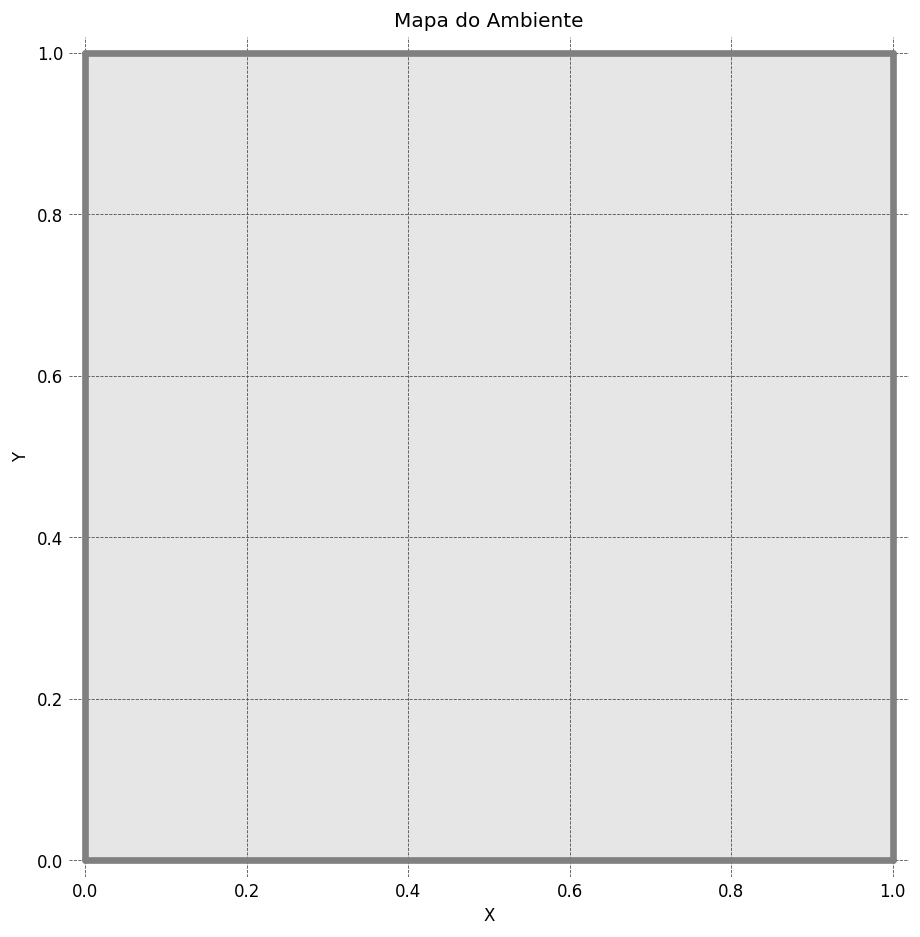

In [149]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), dpi=120)
# for i in range(NUM_OF_CUES):
#     plt.annotate(text=i+1, xy=Env.objects['objects'][i],fontweight='bold', fontsize=10)
Env.plot_environment(gridlines=True, fig=fig, ax=ax,) #visualises current environment with walls and objects
plt.title('Mapa do Ambiente')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

### Num of Cues

In [150]:
Env.has_holes

False

### RUN PARAMETERS

In [151]:
CUE_NAME_LEN = 4
MAX_NUMBER_OF_CUES = 5
# CONTEXT_LEN = MAX_NUMBER_OF_CUES*CUE_NAME_LEN
# CONTEXT_LEN

### gerando cues positions

In [152]:
CUES_LIST = gerar_grade_com_ruido(5, )

In [153]:
CUES_LIST[:3]

[(0.0020185139676535263, 0.0),
 (0.0, 0.27869456184367947),
 (0.0004996289354662987, 0.4877059749484163)]

In [154]:
NUM_OF_CUES = len(CUES_LIST)
NUM_OF_CUES

25

In [155]:
# CUES_LIST = []
# num_test = 0
# for i in range(NUM_OF_CUES):
#     candidate_point = np.random.rand(), np.random.rand()
#     CUES_LIST.append(candidate_point)
# print(f'{NUM_OF_CUES} cues criadas com {num_test} candidatos')

### gerando all positions df

In [156]:
# apd = pd.read_parquet('legacy/datasets/apd_full.gzip')

In [157]:
# apd.columns

## recreating objs pos and names

In [158]:
obj_name_cols = [f"obj_{i}_name" for i in range(25)]
obj_pos_cols = [f"obj_{i}_pos" for i in range(25)]

In [159]:
# apd["obj_10_pos"].values

In [160]:
# CUES_LIST = [apd[feat].values[0] for feat in obj_pos_cols]

In [161]:
# with open('legacy/auxiliary/CUES_LIST.pkl', 'wb') as fil:
#     pickle.dump(CUES_LIST, fil)

In [162]:
with open('legacy/auxiliary/CUES_LIST.pkl', 'rb') as f:
    CUES_LIST = pickle.load(f)

In [163]:
CUES_LIST[:3]

[array([0.02256549, 0.02753175]),
 array([0.        , 0.25205916]),
 array([0.        , 0.48541027])]

In [164]:
# sorted_obj_name_cols = []

In [165]:
# ap = generate_all_positions_on_env(hole=None)
# ap.head()

In [166]:
# ap.shape

### adicionando cues ao EnV

In [167]:
for point in CUES_LIST:
    Env.add_object(object=point,type=0)

In [168]:
len(Env.objects['objects']), NUM_OF_CUES

(25, 25)

In [169]:
Env.objects['objects'][:3]

array([[0.02256549, 0.02753175],
       [0.        , 0.25205916],
       [0.        , 0.48541027]])

In [170]:
objects_name_list = []
for i in range(NUM_OF_CUES):
    obj_name = generate_random_string(CUE_NAME_LEN)
    if obj_name in objects_name_list:
        obj_name = generate_random_string(CUE_NAME_LEN)
    objects_name_list.append(obj_name)

In [171]:
len(objects_name_list), len(set(objects_name_list))

(25, 25)

In [172]:
objects_name_list[:3]

['LQSN', 'JESL', 'GTCS']

In [173]:
# objects_name_list = [apd[feat].values[0] for feat in obj_name_cols]

In [174]:
with open('legacy/auxiliary/objects_name_list.pkl', 'rb') as f:
    objects_name_list = pickle.load(f)

In [175]:
objects_name_list[:3]

['COQV', 'MTAS', 'HOBB']

In [176]:
# with open('legacy/auxiliary/objects_name_list.pkl', 'wb') as fil:
#     pickle.dump(objects_name_list, fil)

In [177]:
objects_name_list[:3]

['COQV', 'MTAS', 'HOBB']

In [178]:
Env.objects['object_names'] = objects_name_list

In [179]:
# Env.objects

## vizz env

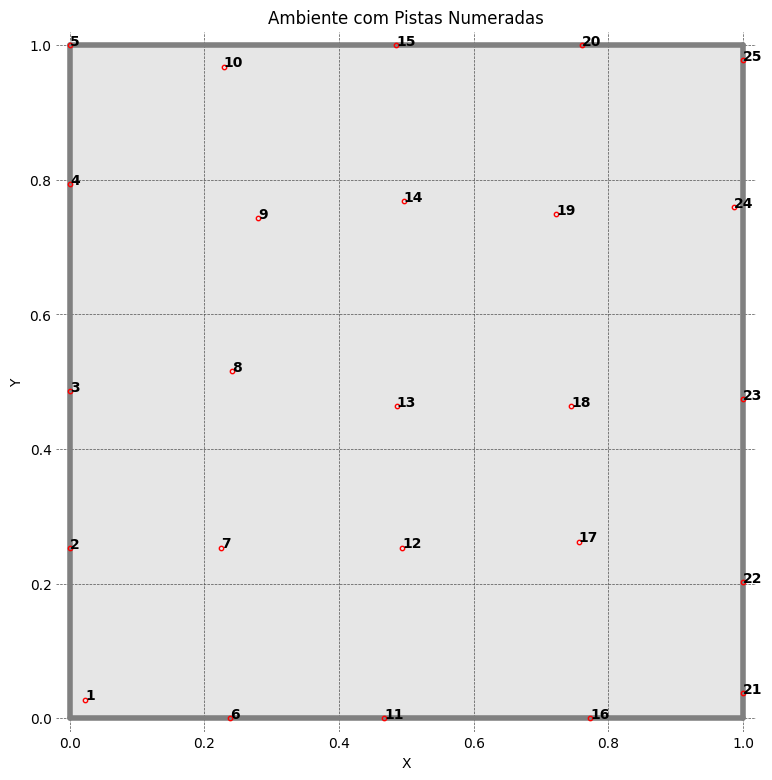

In [180]:
fig, ax = plt.subplots(1, 1, figsize=(14,7))
for i in range(NUM_OF_CUES):
    plt.annotate(text=i+1, xy=Env.objects['objects'][i],fontweight='bold', fontsize=10)
Env.plot_environment(gridlines=True, fig=fig, ax=ax,) #visualises current environment with walls and objects
plt.title('Ambiente com Pistas Numeradas')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

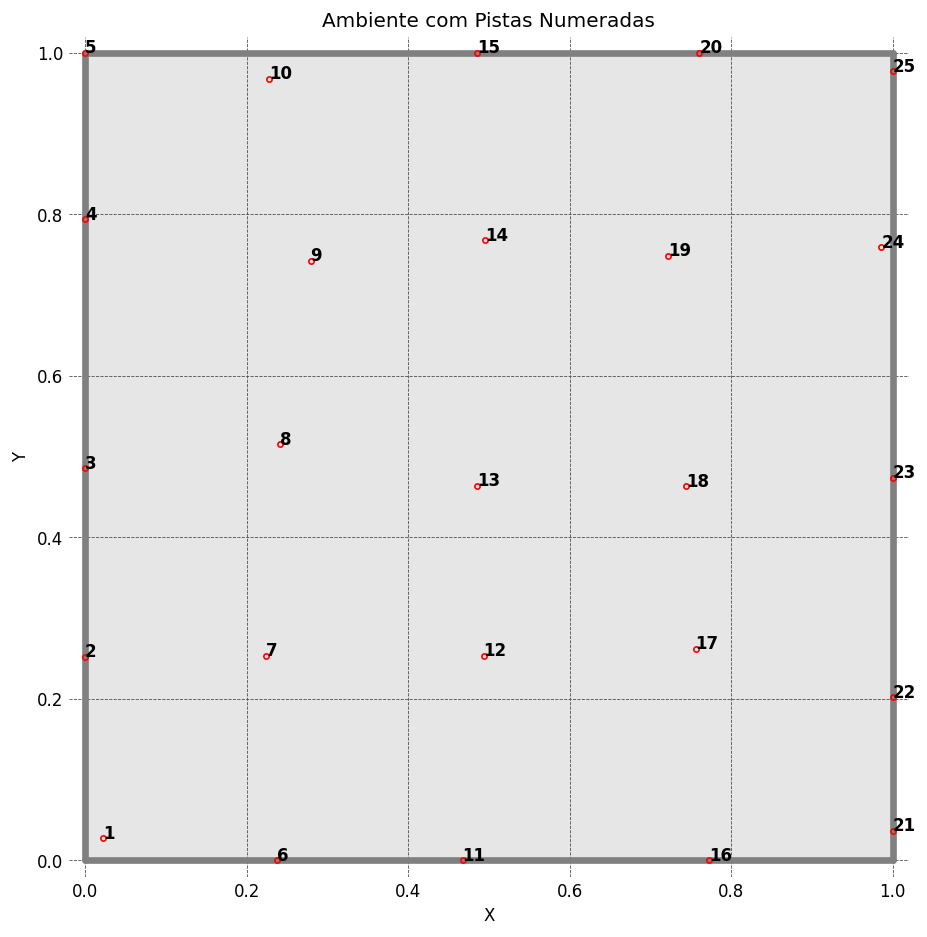

In [181]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), dpi=120)
for i in range(NUM_OF_CUES):
    plt.annotate(text=i+1, xy=Env.objects['objects'][i],fontweight='bold', fontsize=10)
Env.plot_environment(gridlines=True, fig=fig, ax=ax,) #visualises current environment with walls and objects
plt.title('Ambiente com Pistas Numeradas')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

In [182]:
help(Env.plot_environment)

Help on method plot_environment in module ratinabox.Environment:

plot_environment(fig=None, ax=None, gridlines=False, plot_objects=True, autosave=None, **kwargs) method of ratinabox.Environment.Environment instance
    Plots the environment (in 1D space is plotted along the x axis), dark grey lines show the walls
    Args:
        fig,ax: the fig and ax to plot on (can be None)
        gridlines: if True, plots gridlines
        plot_objects: if True, plots objects
        autosave: if True, will try to save the figure to the figure directory `ratinabox.figure_directory`. Defaults to None in which case looks for global constant ratinabox.autosave_plots
    Returns:
        fig, ax: the environment figures, can be used for further downstream plotting.



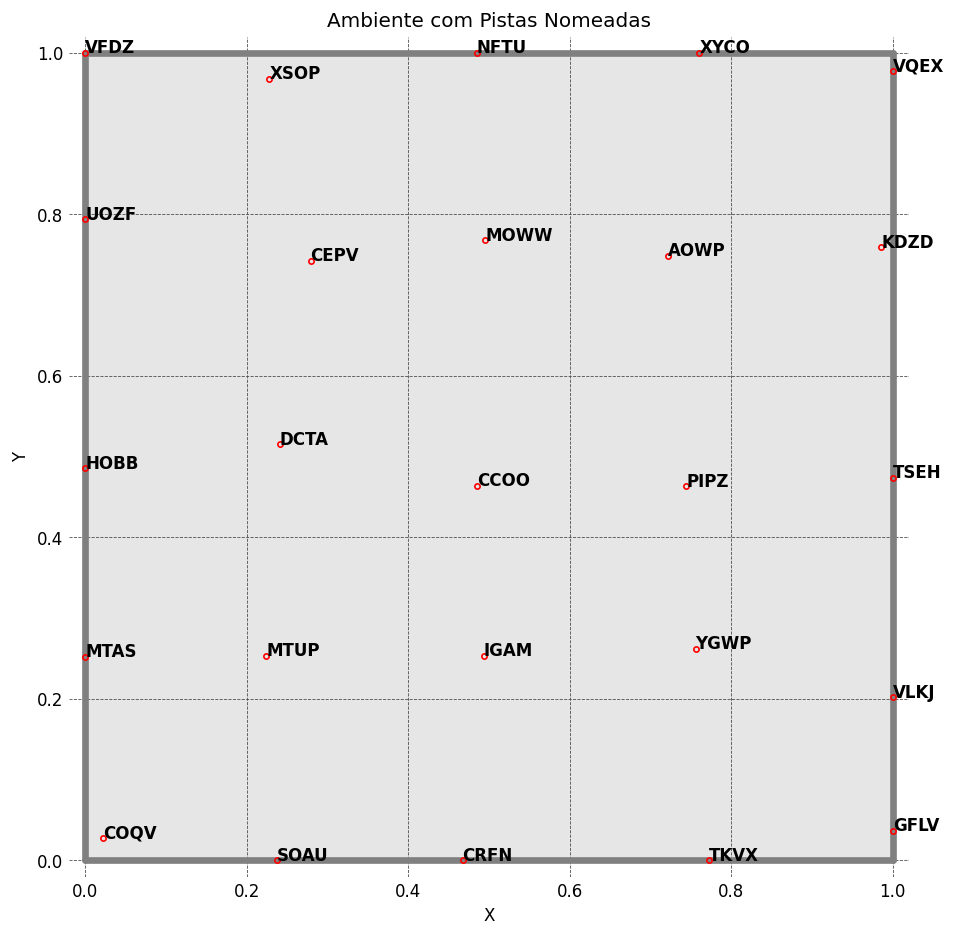

In [183]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), dpi=120)
for i in range(NUM_OF_CUES):
    plt.annotate(text=Env.objects['object_names'][i], xy=Env.objects['objects'][i],fontweight='bold', fontsize=10)
Env.plot_environment(gridlines=True, fig=fig, ax=ax,) #visualises current environment with walls and objects
plt.title('Ambiente com Pistas Nomeadas')
plt.xlabel('X')
plt.ylabel('Y')
plt.show()

In [184]:
# Agent()

In [185]:
# help(Agent)

## define Ag

In [186]:
Ag = Agent(Environment=Env)#, params={'speed_mean':0.08,})

# agent configs
# Ag.pos = start_pos
# Ag.thigmotaxis = 0.2
# Ag.dt = 0.05

In [187]:
# help(Agent)

In [188]:
f = Ag.import_trajectory(dataset='sargolini')

Attempting to import Sargolini locomotion dataset.
                    Please cite Sargolini et al. (2006) DOI:10.1126/science.1125572 if you use this in your work.
                    The full dataset (along with many more) can be found here https://www.ntnu.edu/kavli/research/grid-cell-data
                    The exact datafile being used is 8F6BE356-3277-475C-87B1-C7A977632DA7_1/11084-03020501_t2c1.mat
Successfully imported dataset from /home/mgteus/workspace/navitrans/.nav/lib/python3.10/site-packages/ratinabox/data/sargolini.npz
Total of 599.6 s of data available


In [189]:
MINUTES = 10

In [190]:
help(Ag.plot_trajectory)

Help on method plot_trajectory in module ratinabox.Agent:

plot_trajectory(t_start=0, t_end=None, framerate=10, fig=None, ax=None, plot_all_agents=False, color=None, colorbar=False, autosave=None, **kwargs) method of ratinabox.Agent.Agent instance
    Plots the trajectory between t_start (seconds) and t_end (defaulting to the last time available)
    Args:
        • t_start: start time in seconds
        • t_end: end time in seconds (default = self.history["t"][-1])
        • framerate: how many scatter points / per second of motion to display
        • fig, ax: the fig, ax to plot on top of, optional, if not provided used self.Environment.plot_Environment().
          This can be used to plot trajectory on top of receptive fields etc.
        • plot_all_agents: if True, this will plot the trajectory of all agents in the list self.Environment.Agents
        • color: plot point color, if color == 'changing' will smoothly change trajectory color from start to finish
        • colorbar: i

### ag update

In [191]:
Ag.history

{'t': [],
 'pos': [],
 'distance_travelled': [],
 'vel': [],
 'rot_vel': [],
 'head_direction': []}

In [192]:
MINUTES*60/Ag.dt

12000.0

In [193]:
for i in range(int(MINUTES*60/Ag.dt)):
    Ag.update()

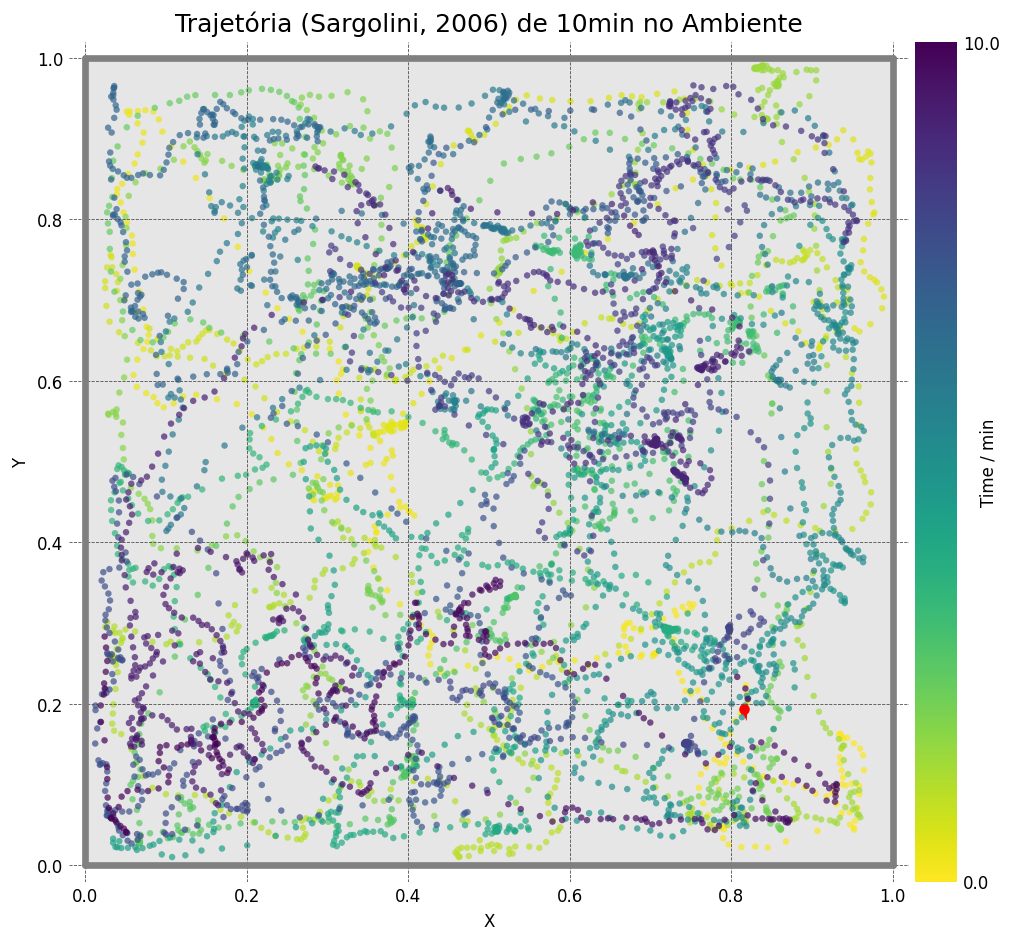

In [194]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), dpi=120)
# for i in range(NUM_OF_CUES):
#     plt.annotate(text=i+1, xy=Env.objects['objects'][i], fontsize=10)
plt.title('Trajetória (Sargolini, 2006) de 10min no Ambiente', fontsize=15)
plt.ylabel('Y')
plt.xlabel('X')
ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, plot_objects=False)

plt.show()

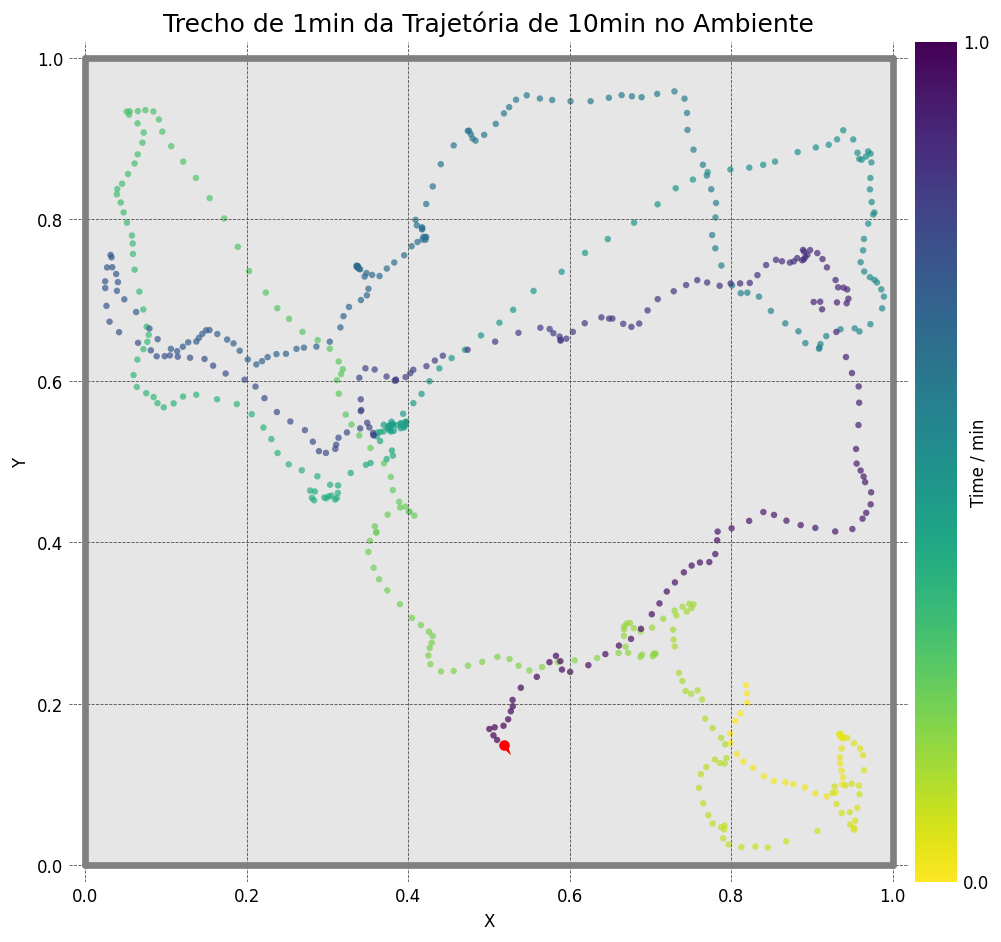

In [195]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), dpi=120)
# for i in range(NUM_OF_CUES):
#     plt.annotate(text=i+1, xy=Env.objects['objects'][i], fontsize=10)
plt.title('Trecho de 1min da Trajetória de 10min no Ambiente', fontsize=15)
plt.ylabel('Y')
plt.xlabel('X')
# plt.scatter(dfbase['pos'].values[0][0],dfbase['pos'].values[0][1], c='k', label=r'$p_1$' )
ax = Ag.plot_trajectory(t_start=0, t_end=60,
    color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, plot_objects=False)
plt.show()

# init dfbase

In [196]:
dfbase = pd.DataFrame(Ag.history).copy()
print(dfbase.shape)
dfbase.head(2)

(12000, 6)


,t,pos,distance_travelled,vel,rot_vel,head_direction
0,0.05,"[0.8181828654676007, 0.2230002800732933]",0.011731,"[0.16667094432077256, -0.16512082862268296]",-31.617083,"[0.9445776820598348, 0.32828798722230085]"
1,0.10,"[0.8175994360456442, 0.21987141323220027]",0.014914,"[-0.011668588439128769, -0.06257733682186073]",-19.488144,"[0.9821734875974579, -0.18797670137718217]"


In [197]:
dfbase['distance_travelled'].diff().describe()

count    11999.000000
mean         0.006073
std          0.008214
min          0.000021
25%          0.003058
50%          0.005226
75%          0.008103
max          0.784173
Name: distance_travelled, dtype: float64

### dfbase metrics

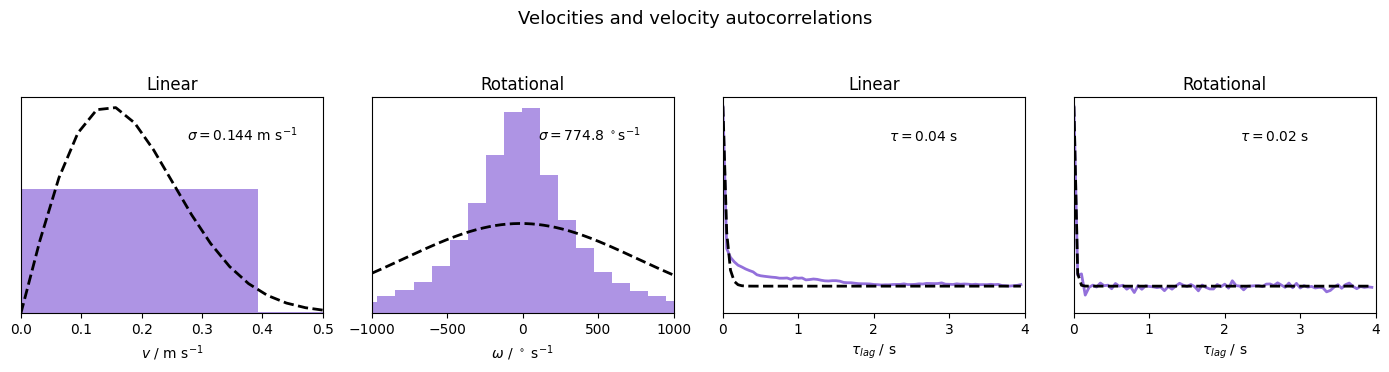

In [198]:
fig, axes, stats_riab = plot_riab_velocity_statistics(
    dfbase,
    tmax=None,
)

plt.show()

Média da velocidade linear: 0.121462 m/s
Desvio padrão da velocidade linear: 0.164285 m/s


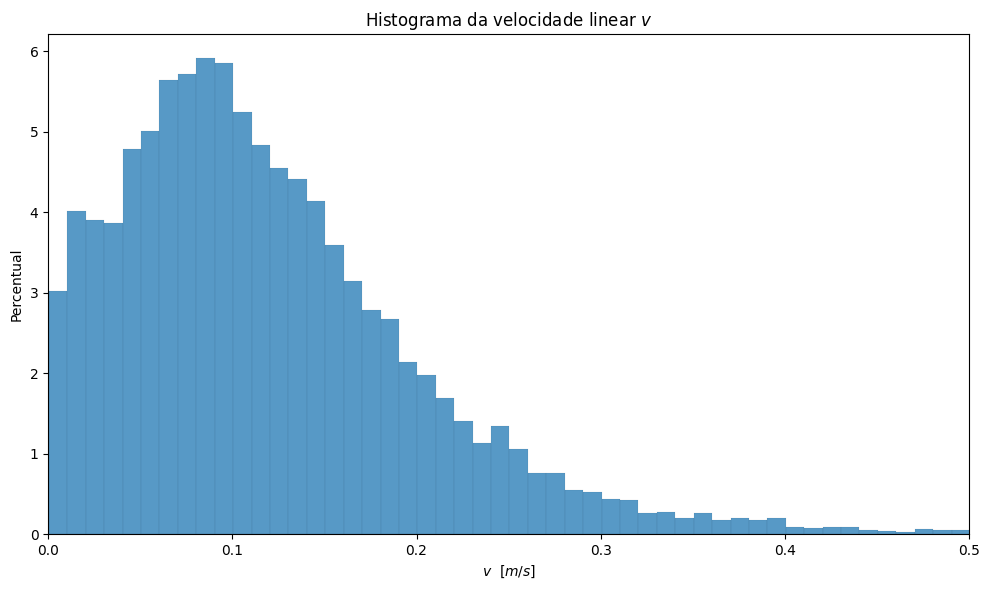

In [199]:
fig, ax, speed = plot_linear_velocity_histogram(dfbase, figsize=(10,6))

In [200]:
Env.objects

{'objects': array([[0.02256549, 0.02753175],
        [0.        , 0.25205916],
        [0.        , 0.48541027],
        [0.        , 0.79356437],
        [0.        , 1.        ],
        [0.23786904, 0.        ],
        [0.22447871, 0.25338321],
        [0.2411788 , 0.51531554],
        [0.27922937, 0.74258662],
        [0.22831091, 0.96791596],
        [0.46741666, 0.        ],
        [0.49344195, 0.2533898 ],
        [0.48570195, 0.46397676],
        [0.49580923, 0.7676767 ],
        [0.4850393 , 1.        ],
        [0.77276843, 0.        ],
        [0.75593301, 0.26204251],
        [0.74465729, 0.46327552],
        [0.72228986, 0.74859963],
        [0.76051646, 1.        ],
        [1.        , 0.03661343],
        [1.        , 0.20163716],
        [1.        , 0.47384793],
        [0.98606977, 0.75935676],
        [1.        , 0.97706269]]),
 'object_types': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0]),
 'object_names': ['COQV',
  

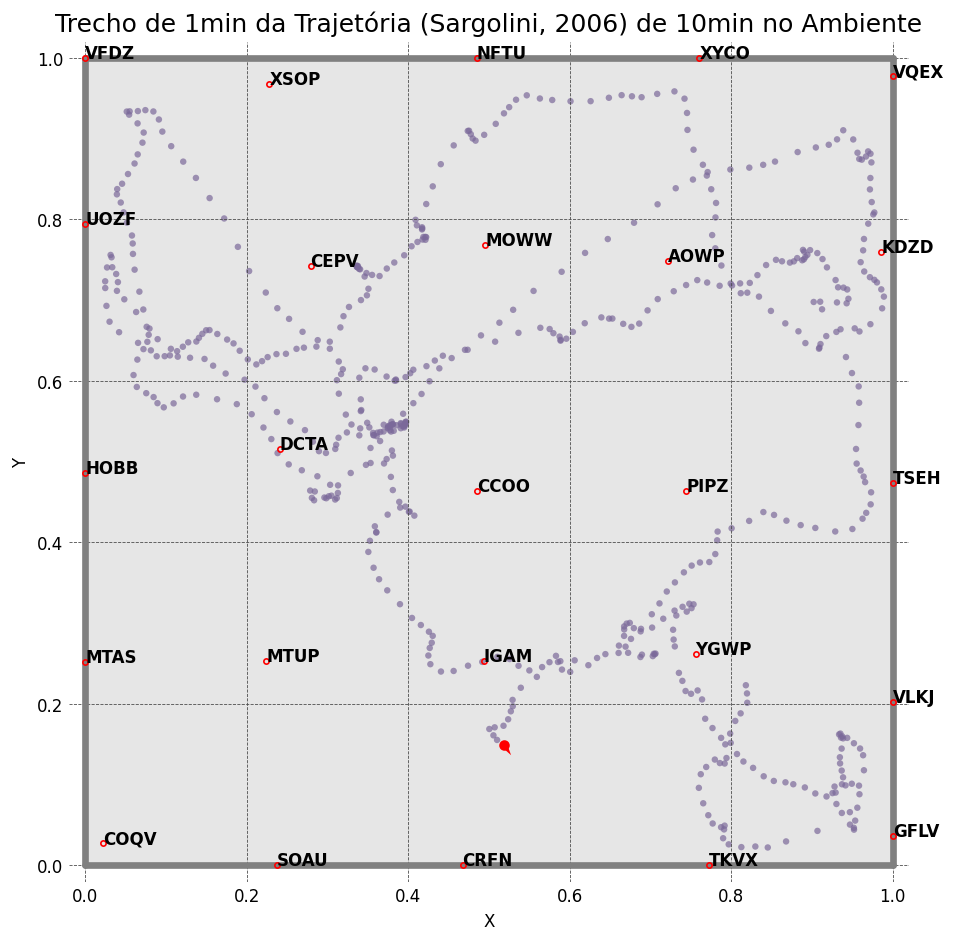

In [201]:
fig, ax = plt.subplots(1, 1, figsize=(14,7), dpi=120)
for i in range(NUM_OF_CUES):
    plt.annotate(text=Env.objects['object_names'][i], xy=Env.objects['objects'][i], fontsize=10, fontweight='bold',)
plt.title('Trecho de 1min da Trajetória (Sargolini, 2006) de 10min no Ambiente', fontsize=15)
plt.ylabel('Y')
plt.xlabel('X')
ax = Ag.plot_trajectory(t_start=0, t_end=60, colorbar=False, gridlines=True,fig=fig, ax=ax)

plt.show()

In [202]:
help(Ag.plot_trajectory)

Help on method plot_trajectory in module ratinabox.Agent:

plot_trajectory(t_start=0, t_end=None, framerate=10, fig=None, ax=None, plot_all_agents=False, color=None, colorbar=False, autosave=None, **kwargs) method of ratinabox.Agent.Agent instance
    Plots the trajectory between t_start (seconds) and t_end (defaulting to the last time available)
    Args:
        • t_start: start time in seconds
        • t_end: end time in seconds (default = self.history["t"][-1])
        • framerate: how many scatter points / per second of motion to display
        • fig, ax: the fig, ax to plot on top of, optional, if not provided used self.Environment.plot_Environment().
          This can be used to plot trajectory on top of receptive fields etc.
        • plot_all_agents: if True, this will plot the trajectory of all agents in the list self.Environment.Agents
        • color: plot point color, if color == 'changing' will smoothly change trajectory color from start to finish
        • colorbar: i

In [203]:
# # ===== subamostragem baseada em frequência alvo =====

# SAMPLE_FREQUENCY = 6  # Hz
# original_frequency = 20

# # calcula STEP (inteiro)
# STEP = max(1, int(round(original_frequency / SAMPLE_FREQUENCY)))

# print(f"Frequência original: {original_frequency:.2f} Hz")
# print(f"STEP escolhido: {STEP}")

# # copia o dataframe completo
# df = dfbase.copy().reset_index(drop=True)

# # cria coluna booleana de amostragem
# df["is_theta_sampled"] = [int(val) for val in (df.index % STEP == 0)]

# print(df.shape)
# df.head(10)

In [234]:
df = dfbase.copy()

In [235]:
df.columns[df.columns.duplicated()].tolist()

[]

## adding obj pos and names to dfbase

In [236]:
Env.objects.keys()

dict_keys(['objects', 'object_types', 'object_names'])

In [237]:
for i in range(NUM_OF_CUES):
    cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in df.index],
         f'obj_{i}_name':[Env.objects['object_names'][i] for _ in df.index],}
    cue_df = pd.DataFrame(data=cue_dict, index=df.index)  
    df = pd.concat([df, cue_df], axis=1)

In [238]:
df.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,obj_20_pos,obj_20_name,obj_21_pos,obj_21_name,obj_22_pos,obj_22_name,obj_23_pos,obj_23_name,obj_24_pos,obj_24_name
0,0.05,"[0.8181828654676007, 0.2230002800732933]",0.011731,"[0.16667094432077256, -0.16512082862268296]",-31.617083,"[0.9445776820598348, 0.32828798722230085]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
1,0.10,"[0.8175994360456442, 0.21987141323220027]",0.014914,"[-0.011668588439128769, -0.06257733682186073]",-19.488144,"[0.9821734875974579, -0.18797670137718217]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
2,0.15,"[0.8195847065625171, 0.21282334198892955]",0.022236,"[0.039705410337458336, -0.14096142486541452]",9.178052,"[0.8579642766522511, -0.5137093536121176]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
3,0.20,"[0.8206160617591811, 0.2067723162065261]",0.028374,"[0.02062710393327949, -0.1210205156480687]",-2.114795,"[0.6832790148882467, -0.7301573719502852]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
4,0.25,"[0.819897771622558, 0.20128463241547787]",0.033909,"[-0.01436580273246335, -0.10975367582096496]",-5.979424,"[0.4503702408315647, -0.8928418931553999]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX


In [239]:
# df.to_parquet('legacy/datasets/traject_with_vis.gzip')
# df = pd.read_parquet('legacy/datasets/traject_with_vis.gzip')

In [240]:
# df.info()

In [241]:
# for i in range(NUM_OF_CUES):
#     cue_dict = {f'obj_{i}_pos':[Env.objects['objects'][i] for _ in ap.index],
#          f'obj_{i}_name':[Env.objects['object_names'][i] for _ in ap.index]}
#     cue_ap = pd.DataFrame(data=cue_dict, index=ap.index)  
#     ap = pd.concat([ap, cue_ap], axis=1)
#     # df[f'obj_{i}_pos'] = [Env.objects['objects'][i] for _ in df.index]
#     # df[f'obj_{i}_name'] = [Env.objects['object_names'][i] for _ in df.index]

In [242]:
# ap.head()

In [243]:
# df.shape, ap.shape

In [244]:
df.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,obj_20_pos,obj_20_name,obj_21_pos,obj_21_name,obj_22_pos,obj_22_name,obj_23_pos,obj_23_name,obj_24_pos,obj_24_name
0,0.05,"[0.8181828654676007, 0.2230002800732933]",0.011731,"[0.16667094432077256, -0.16512082862268296]",-31.617083,"[0.9445776820598348, 0.32828798722230085]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX
1,0.10,"[0.8175994360456442, 0.21987141323220027]",0.014914,"[-0.011668588439128769, -0.06257733682186073]",-19.488144,"[0.9821734875974579, -0.18797670137718217]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,"[1.0, 0.03661342911221448]",GFLV,"[1.0, 0.20163715696792245]",VLKJ,"[1.0, 0.47384793352524796]",TSEH,"[0.9860697712267116, 0.7593567577581513]",KDZD,"[1.0, 0.9770626899875797]",VQEX


In [245]:
# ap.shape

## measure distances and visibility to objs

In [246]:
df = compute_visibility_and_distances(
    env=Env,
    df=df,
    num_of_cues=NUM_OF_CUES,
    half_fov_deg=180.,   # biologico
    min_distance=0.02,
    max_distance=1.,
)


df.head(2)

/tmp/ipykernel_33801/780080056.py:68: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"rel_angle_deg_obj_{i}"] = relative_angle_deg[:, i]
/tmp/ipykernel_33801/780080056.py:69: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"los_obj_{i}"] = [int(val) for val in line_of_sight[:, i]]


,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,rel_angle_deg_obj_22,los_obj_22,dist_to_obj_23,visible_obj_23,rel_angle_deg_obj_23,los_obj_23,dist_to_obj_24,visible_obj_24,rel_angle_deg_obj_24,los_obj_24
0,0.05,"[0.8181828654676007, 0.2230002800732933]",0.011731,"[0.16667094432077256, -0.16512082862268296]",-31.617083,"[0.9445776820598348, 0.32828798722230085]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,34.900091,1,0.562018,1,53.454271,1,0.775672,1,57.278882,1
1,0.10,"[0.8175994360456442, 0.21987141323220027]",0.014914,"[-0.011668588439128769, -0.06257733682186073]",-19.488144,"[0.9821734875974579, -0.18797670137718217]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,65.149622,1,0.565178,1,83.492204,1,0.778851,1,87.290737,1


In [ ]:
# for i in range(NUM_OF_CUES):
#     dist_cue_dict = {f'dist_to_obj_{i}': df.apply(apply_eucd_dist, axis=1, obj=i)}
#     dist_cue_df = pd.DataFrame(data=dist_cue_dict, index=df.index)
#     df = pd.concat([df, dist_cue_df], axis=1)

In [217]:
# for i in range(NUM_OF_CUES):
#     dist_cue_dict = {f'dist_to_obj_{i}': ap.apply(apply_eucd_dist, axis=1, obj=i)}
#     dist_cue_ap = pd.DataFrame(data=dist_cue_dict, index=ap.index)
#     ap = pd.concat([ap, dist_cue_ap], axis=1)

In [218]:
# ap.head()

In [219]:
# df.columns

In [220]:
# df[[feat for feat in df.columns if feat.startswith('dist_')]].mean()

In [221]:
# fig, ax = plt.subplots(1, 1, figsize=(14,7))
# for i in range(NUM_OF_CUES):
#     plt.annotate(text=i+1, xy=Env.objects['objects'][i], fontsize=10, fontweight='bold')
# ax = Ag.plot_trajectory(color='changing', colorbar=True, gridlines=True,fig=fig, ax=ax, t_start=0, t_end=df['t'].max())

# plt.show()

In [247]:
obj_names = [Env.objects['object_names'][i] for i in range(NUM_OF_CUES)]
obj_dist_cols = [f'dist_to_obj_{i}' for i in range(NUM_OF_CUES)]

# # def get_position_text(x):

In [248]:
# obj_names = [Env.objects['object_names'][i] for i in range(NUM_OF_CUES)]
obj_dist_cols = [f'dist_to_obj_{i}' for i in range(NUM_OF_CUES)]
obj_visible_cols = [f'visible_obj_{i}' for i in range(NUM_OF_CUES)]

In [249]:
df.columns[df.columns.duplicated()].tolist()

[]

In [250]:
obj_dist_cols[:4]

['dist_to_obj_0', 'dist_to_obj_1', 'dist_to_obj_2', 'dist_to_obj_3']

In [251]:
obj_visible_cols[:4]

['visible_obj_0', 'visible_obj_1', 'visible_obj_2', 'visible_obj_3']

In [252]:
df.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,rel_angle_deg_obj_22,los_obj_22,dist_to_obj_23,visible_obj_23,rel_angle_deg_obj_23,los_obj_23,dist_to_obj_24,visible_obj_24,rel_angle_deg_obj_24,los_obj_24
0,0.05,"[0.8181828654676007, 0.2230002800732933]",0.011731,"[0.16667094432077256, -0.16512082862268296]",-31.617083,"[0.9445776820598348, 0.32828798722230085]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,34.900091,1,0.562018,1,53.454271,1,0.775672,1,57.278882,1
1,0.10,"[0.8175994360456442, 0.21987141323220027]",0.014914,"[-0.011668588439128769, -0.06257733682186073]",-19.488144,"[0.9821734875974579, -0.18797670137718217]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,65.149622,1,0.565178,1,83.492204,1,0.778851,1,87.290737,1
2,0.15,"[0.8195847065625171, 0.21282334198892955]",0.022236,"[0.039705410337458336, -0.14096142486541452]",9.178052,"[0.8579642766522511, -0.5137093536121176]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,86.259726,1,0.571328,1,103.969436,1,0.785246,1,107.628497,1
3,0.20,"[0.8206160617591811, 0.2067723162065261]",0.028374,"[0.02062710393327949, -0.1210205156480687]",-2.114795,"[0.6832790148882467, -0.7301573719502852]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,103.011921,1,0.576823,1,120.230944,1,0.790902,1,123.790292,1
4,0.25,"[0.819897771622558, 0.20128463241547787]",0.033909,"[-0.01436580273246335, -0.10975367582096496]",-5.979424,"[0.4503702408315647, -0.8928418931553999]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,119.776944,1,0.582287,1,136.651091,1,0.796410,1,140.162478,1


## create positions

In [253]:
dfp = apply_cps_to_positions_with_vizz(df, obj_dist_cols, obj_visible_cols)
dfp.shape

(12000, 159)

In [ ]:
dfp.head()

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,visible_obj_23,rel_angle_deg_obj_23,los_obj_23,dist_to_obj_24,visible_obj_24,rel_angle_deg_obj_24,los_obj_24,position_state,mean_distance_visible,n_visible_objects
0,0.05,"[0.818, 0.223]",0.011731,"[0.16667094432077256, -0.16512082862268296]",-1.552017,"[0.745847576344106, -0.666116651091701]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1,114.387216,1,0.775672,1,118.211827,1,YGWPVLKJTKVXPIPZGFLV,0.199156,24
1,0.10,"[0.818, 0.22]",0.014914,"[-0.011668588439128769, -0.06257733682186073]",-19.488144,"[0.49198498746039165, -0.8706036825752567]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1,133.186341,1,0.778851,1,136.984874,1,YGWPVLKJTKVXPIPZGFLV,0.199014,24
2,0.15,"[0.82, 0.213]",0.022236,"[0.039705410337458336, -0.14096142486541452]",9.178052,"[0.42105116896262784, -0.9070368863035311]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1,138.157240,1,0.785246,1,141.816302,1,YGWPVLKJTKVXGFLVPIPZ,0.198549,23
3,0.20,"[0.821, 0.207]",0.028374,"[0.02062710393327949, -0.1210205156480687]",-2.114795,"[0.3393658692426399, -0.9406544566381364]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1,143.493111,1,0.790902,1,147.052460,1,YGWPVLKJTKVXGFLVPIPZ,0.198308,23
4,0.25,"[0.82, 0.201]",0.033909,"[-0.01436580273246335, -0.10975367582096496]",-5.979424,"[0.18768540383598473, -0.9822291938172696]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1,152.600794,1,0.796410,1,156.112181,1,YGWPVLKJTKVXGFLVPIPZ,0.198334,23


In [255]:
# dfp.iloc[34:90][['t', 'position_state', 'position_state_id']]

In [256]:
dfp['position_state_id'] = dfp.groupby(['position_state']).ngroup() + 1 
dfp['position_state_id'].nunique()

771

In [257]:
dfp['position_state_id'].value_counts()

position_state_id
505    166
52     165
527    111
195    109
63     106
      ... 
82       1
450      1
502      1
499      1
486      1
Name: count, Length: 771, dtype: int64

In [258]:
num_unique_pos = dfp['position_state'].nunique()
num_unique_pos

771

In [259]:
dfp['normalized_position_state_id']  = (dfp['position_state_id'] / dfp['position_state_id'].nunique())
dfp[['position_state_id', 'normalized_position_state_id']].sample(5)

,position_state_id,normalized_position_state_id
1840,712,0.923476
5217,195,0.252918
10815,527,0.683528
10592,123,0.159533
5962,345,0.447471


In [260]:
# apd.head()

In [261]:
# apd[['obj_0_name', 'obj_0_pos']].values

## get change of pos

In [262]:
dfp['last_position_state_id'] = (dfp['position_state_id'].shift(1))
dfp.shape

(12000, 162)

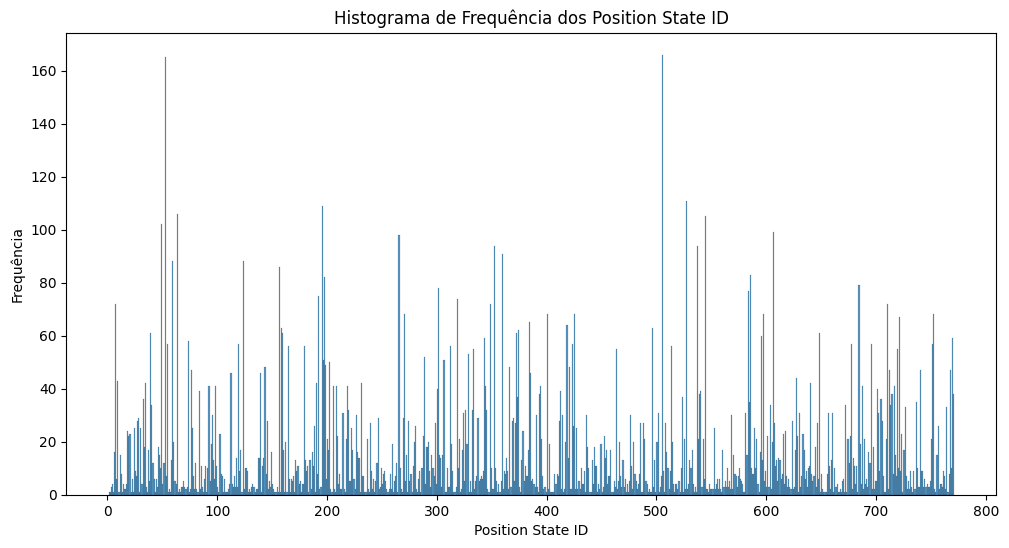

In [263]:
fig, ax = plt.subplots(figsize=(12, 6))
plt.title('Histograma de Frequência dos Position State ID')
sns.histplot(dfp['position_state_id'],binwidth=1,)
plt.ylabel('Frequência')
plt.xlabel('Position State ID')
plt.show()

In [264]:
change_dict_ = {'change_of_position_state':[int(pos!=last_pos) for pos, last_pos in zip(dfp['position_state_id'].astype('float'), dfp['last_position_state_id'])]}
change_dict_df = pd.DataFrame(change_dict_)

print(change_dict_df.shape)
# dfp = pd.concat([dfp, change_dict_df], ignore_index=True, axis=0)

(12000, 1)


In [265]:
dfp['change_of_position_state'] = (change_dict_df['change_of_position_state'])

In [266]:
dfp.shape

(12000, 163)

In [267]:
# dfp['change_of_position_state'].values

In [268]:
dfp[['position_state', 'position_state_id', 'last_position_state_id', 'change_of_position_state']].iloc[8:12]

,position_state,position_state_id,last_position_state_id,change_of_position_state
8,YGWPTKVXVLKJGFLVPIPZ,751,751.0,0
9,YGWPTKVXVLKJGFLVPIPZ,751,751.0,0
10,YGWPTKVXVLKJGFLVPIPZ,751,751.0,0
11,YGWPTKVXVLKJGFLVPIPZ,751,751.0,0


In [269]:
dfp[dfp['change_of_position_state'] == 1][['position_state_id', 'last_position_state_id', 'change_of_position_state']].head()

,position_state_id,last_position_state_id,change_of_position_state
0,770,NaN,1
2,769,770.0,1
7,751,769.0,1
15,612,751.0,1
19,608,612.0,1


In [270]:
dfp[dfp['change_of_position_state'] == 1].shape

(2685, 163)

In [271]:
dfp['change_of_position_state'].mean()

0.22375

# train df

In [279]:
dfc = dfp[dfp['change_of_position_state'] == 1].iloc[1:].reset_index(drop=True).copy()
dfc.shape

(2684, 163)

In [280]:
dfc.head(2)

,t,pos,distance_travelled,vel,rot_vel,head_direction,obj_0_pos,obj_0_name,obj_1_pos,obj_1_name,...,visible_obj_24,rel_angle_deg_obj_24,los_obj_24,position_state,mean_distance_visible,n_visible_objects,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.15,"[0.8195847065625171, 0.21282334198892955]",0.022236,"[0.039705410337458336, -0.14096142486541452]",9.178052,"[0.8579642766522511, -0.5137093536121176]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1,107.628497,1,YGWPVLKJTKVXGFLVPIPZ,0.198549,23,769,0.997406,770.0,1
1,0.40,"[0.8084176057915655, 0.1833762902898712]",0.055311,"[-0.06548091434677383, -0.09602170424236667]",1.701201,"[-0.26195302935619863, -0.965080623788039]","[0.022565492455356467, 0.027531754737180482]",COQV,"[0.0, 0.2520591619465594]",MTAS,...,1,-178.384654,1,YGWPTKVXVLKJGFLVPIPZ,0.200447,23,751,0.974060,769.0,1


In [281]:
dfc.columns

Index(['t', 'pos', 'distance_travelled', 'vel', 'rot_vel', 'head_direction',
       'obj_0_pos', 'obj_0_name', 'obj_1_pos', 'obj_1_name',
       ...
       'visible_obj_24', 'rel_angle_deg_obj_24', 'los_obj_24',
       'position_state', 'mean_distance_visible', 'n_visible_objects',
       'position_state_id', 'normalized_position_state_id',
       'last_position_state_id', 'change_of_position_state'],
      dtype='object', length=163)

In [282]:
columns_to_keep = [
    't',
    'pos',
    'distance_travelled',
    'vel',
    'rot_vel',
    'head_direction',
    'position_state',
    'position_state_id',
    'normalized_position_state_id',
    'last_position_state_id',
    'change_of_position_state',
]

### save dfc

In [283]:
save_dfc = True

In [ ]:
# Salva os pontos de mudança para treino e todos os pontos para os mapas espaciais.
if save_dfc:
    dfc[columns_to_keep].to_parquet(
        'sargolini_trainset_squared_25.gzip'
    )
    dfp[columns_to_keep].to_parquet(
        'legacy/datasets/sargolini_trainset_squared_25__all.gzip'
    )

In [ ]:
dfc[columns_to_keep].head(5)

,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.15,"[0.964, 0.586]",0.002947,"[0.01924901314411513, -0.003948870736979841]",-5.345884,"[0.9795991420207817, -0.20096149121696957]",TSEHVLKJGFLVAAAAAAAA,2174,0.820687,NaN,1
1,0.30,"[0.971, 0.588]",0.009698,"[0.04181333823597422, 0.016644679076252743]",3.874422,"[0.929093399643261, 0.3698451767149704]",KDZDVQEXAAAAAAAAAAAA,1288,0.486221,2174.0,1
2,0.45,"[0.977, 0.581]",0.019127,"[0.043567198864500334, -0.04530980505308202]",-7.892169,"[0.6931093661580817, -0.7208324399913908]",TSEHVLKJGFLVTKVXAAAA,2178,0.822197,1288.0,1
3,0.60,"[0.98, 0.584]",0.022705,"[0.017278593097252624, 0.0164440696228955]",10.437458,"[0.7243835452159295, 0.6893971855326954]",KDZDVQEXXYCOAAAAAAAA,1296,0.489241,2178.0,1
4,0.75,"[0.979, 0.585]",0.024160,"[-0.006660281325290285, 0.007051023636108766]",10.446679,"[-0.6866770014356762, 0.7269626508282997]",KDZDPIPZAOWPVQEXXYCO,1265,0.477539,1296.0,1


In [ ]:
def plot_environment_by_state(dfc, env=None, point_size=5):
    """
    Plota o ambiente (x, y) colorido por position_state_id.

    Parameters
    ----------
    dfc : DataFrame
        Deve conter colunas:
            - 'pos' (array [x, y])
            - 'position_state_id'
    env : RatInABox Environment (opcional)
        Se fornecido, plota limites e objetos
    """

    # ---- extrai posições ----
    pos_array = np.vstack(dfc["pos"].values)
    x = pos_array[:, 0]
    y = pos_array[:, 1]

    # ---- estados ----
    states = dfc["position_state_id"].values

    # mapeia estados únicos para cores
    unique_states = np.unique(states)
    n_states = len(unique_states)

    # colormap
    cmap = plt.cm.get_cmap("tab20", n_states)

    state_to_color = {s: cmap(i) for i, s in enumerate(unique_states)}
    colors = np.array([state_to_color[s] for s in states])

    # ---- plot ----
    plt.figure(figsize=(8, 8))
    plt.scatter(x, y, c=states,cmap='viridis', s=point_size)

    # ---- opcional: desenhar ambiente ----
    if env is not None:
        # limites do ambiente
        if hasattr(env, "extent"):
            xmin, xmax, ymin, ymax = env.extent
            plt.xlim(xmin, xmax)
            plt.ylim(ymin, ymax)

        # objetos
        if hasattr(env, "objects"):
            obj_pos = np.array(env.objects["objects"])
            plt.scatter(
                obj_pos[:, 0],
                obj_pos[:, 1],
                c="black",
                s=80,
                marker="x",
                label="objects"
            )

    plt.title("Environment colored by position_state_id")
    plt.xlabel("x")
    plt.ylabel("y")
    plt.axis("equal")

    # legenda simplificada (opcional, pode ficar pesada)
    # plt.legend()

    plt.show()

/tmp/ipykernel_59908/4159453985.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20", n_states)


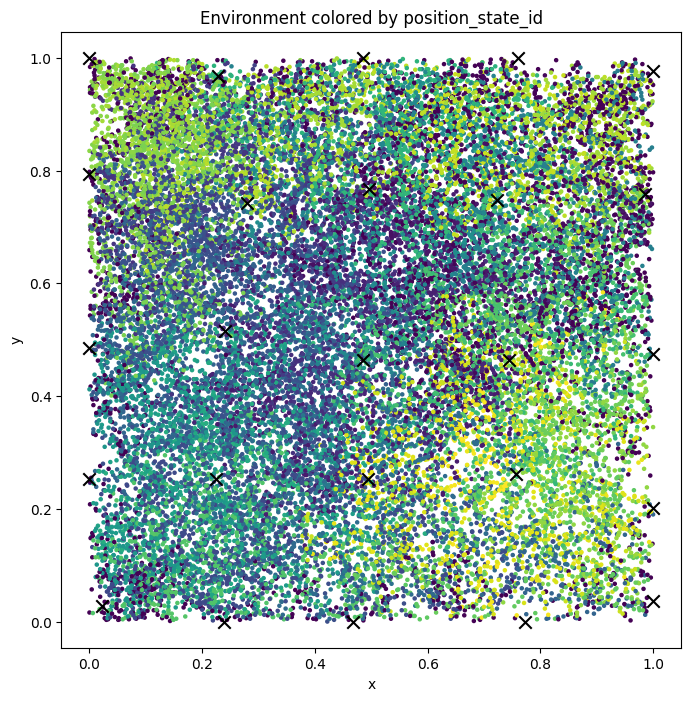

In [ ]:
plot_environment_by_state(dfc, env=Env)

/tmp/ipykernel_59908/4159453985.py:28: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("tab20", n_states)


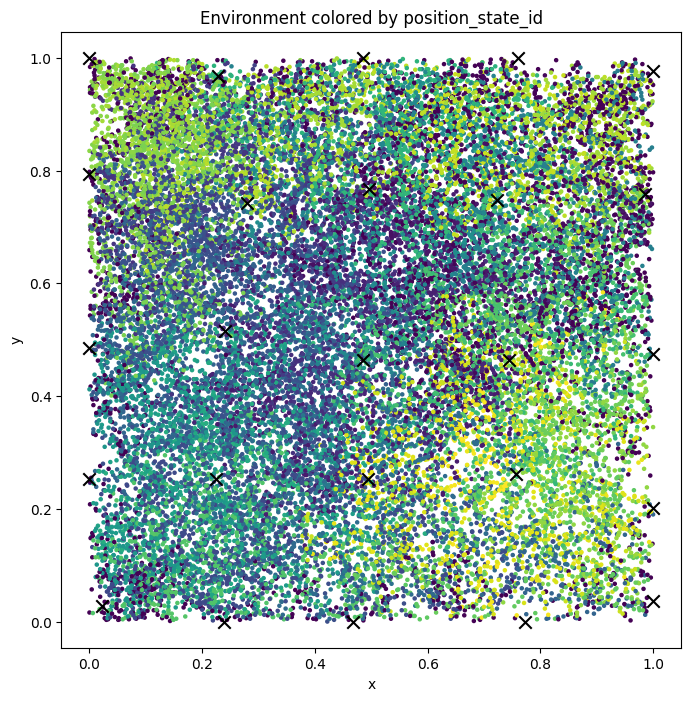

In [ ]:
plot_environment_by_state(dfp, env=Env)

# FIM